In [1]:
#density_waves.ipynb
#by Joe Hahn and Claude Code, joe.hahn@jmh-datasciences.com, 23 November 2026.
#an m = 2 satellite in the ring plane launches a spiral density wave in the self-gravitating ring of bending_waves.ipynb
#(paper Section 4.2.4); show that
#test 10: the ring's radial amplitude |xi|/r follows linear theory, Eqn. (45) of the paper: the wave outside r_L, the forced
#         response inside; the wave is compared where it is steady by the run's end, the resonance zone < x < 0.01
#test 11: the wave's wavenumber k(x), from the radial gradient of its phase, is near the dispersion relation, Eqn. (40),
#         and k > 0, trailing; and the satellite's torque on the ring settles onto linear theory's T_L, Eqn. (46)
#how each quantity is computed, straight from the simulation's output (load3d: every particle's r, theta, v_r, v_theta):
#  xi     each streamline's complex radial displacement, a least-squares fit of its particles' r to
#         r_0 + Re[xi e^{i m(theta - Omega_p t)}] (simulated_xi); x = (r_0 - r_L)/r_L
#  k      d arg(xi - L_L/x)/dr between neighboring streamlines, the wave part of xi, as for the bending wave (B21)
#  T      sum of mu r A_theta over the ring's particles, A_theta the satellite's pull (fast/satellite.py)
#  L_z    sum of mu r v_theta over the ring's particles

In [2]:
#paths and imports
import sys
sys.path.insert(0, '../../source')
sys.path.insert(0, '../../fast')
sys.path.insert(0, '..')
import numpy as np

from density_analysis import (load3d, satellite, simulated_xi, density_wave, ring_sigma, L_L, wave_amplitude,
    wave_wavenumber, wavenumber_profile, satellite_torque, torque_theory, paper_figure, tau_001,
    wave_front, resonance_zone, X_STEADY)

In [3]:
#restore the simulation's output, convert to elements, and fit each streamline's complex displacement xi at the end
p, o = load3d('.')
sat, x, xi = simulated_xi(p, o, -1)
sigma = ring_sigma(p)
print('r.shape = ', o['r'].shape)
for k in ('number_of_streamlines', 'particles_per_streamline', 'radial_width', 'total_ring_mass', 'dt', 'J2', 'Rp'):
    print(k, '=', p[k])
for k, v in sat.summary().items():
    print(k, '=', v)
print('sigma = ', sigma)
print('eccentricity range = ', o['e'].min(), o['e'].max())
print('monitor = ', o['monitor'])

r.shape =  (61, 800, 32)
number_of_streamlines = 800
particles_per_streamline = 32
radial_width = 0.02
total_ring_mass = 3e-08
dt = 0.5
J2 = 0.01
Rp = 0.5
resonance = horizontal
m = 2
mass_final = 2e-10
time_grow = -1.0
r = 1.5902293522815265
t = 0.0
Omega_a = 0.49903628110671744
nu_a = 0.4997746597821818
Omega_p = 0.49903628110671744
r_L = 1.0050000000000003
beta_L = 0.6319843100356004
b_12 = 0.36827927193881443
db_12 = 1.47018993076733
Psi_per_mass = -1.5140794647885651
Psi_final = -3.0281589295771305e-10
D_L = 2.98827007851451
sigma =  2.36368727364201e-07
eccentricity range =  3.442633722565445e-10 3.633029733067483e-06
monitor =  {'start_time': 1795471271, 'current_time': 1795472265, 'current_timestep': 40992, 'streamline_crossing_timestep': None, 'nan_timestep': None, 'self_interacting': True, 'modified_params': None}


In [4]:
#timescales: the wave's group speed c_g = pi G sigma/kappa_a (Eqn. 41), and tau_0.01 = 0.01 r_L/c_g, the time it
#takes to travel from r_L to x = 0.01 (tau_001)
tau = tau_001(p, sat)
orbits = o['times']/(2.0*np.pi)
print('tau_0.01 (orbits) = ', np.round(tau/(2.0*np.pi), 1))
print('run length (orbits) = ', np.round(orbits[-1], 1), '  = ', np.round(o['times'][-1]/tau, 3), ' tau_0.01')
#the wave front at the end, measured where |xi - L_L/x| falls below |Z_w|/2 going outward (wave_front), and the stretch
#where the wave is steady, the resonance zone < x < 0.01 (also used by tools/paper_numbers.py)
x_out = (1.0 + p['radial_width'] - sat.r_L)/sat.r_L
x_front = wave_front(p, o, -1)
x_lo, x_hi = resonance_zone(p, sat), X_STEADY
print('x_outer_edge = ', np.round(x_out, 5), '  x_front = ', np.round(x_front, 5), '  steady: ',
    np.round(x_lo, 5), ' < x < ', np.round(x_hi, 5))

tau_0.01 (orbits) =  2134.0
run length (orbits) =  3262.0   =  1.529  tau_0.01
x_outer_edge =  0.01493   x_front =  0.01363   steady:  0.00141  < x <  0.01


In [5]:
#prep plots
%matplotlib inline
import seaborn as sns
import matplotlib.pyplot as plt
color_seq = plt.rcParams['axes.prop_cycle'].by_key()['color']
sns.set(font_scale=1.5, font='DejaVu Sans')

steady stretch: median |xi - L_L/x|/|Z_w| =  1.0329
nonwave side (x < -2 eps^1/2): median |xi - theory|/|theory| =  0.0121    largest =  0.0339
first output: mean eccentricity at the inner edge, mid-ring and outer edge =  [3.36993873e-06 3.97998418e-08 3.48949729e-06]


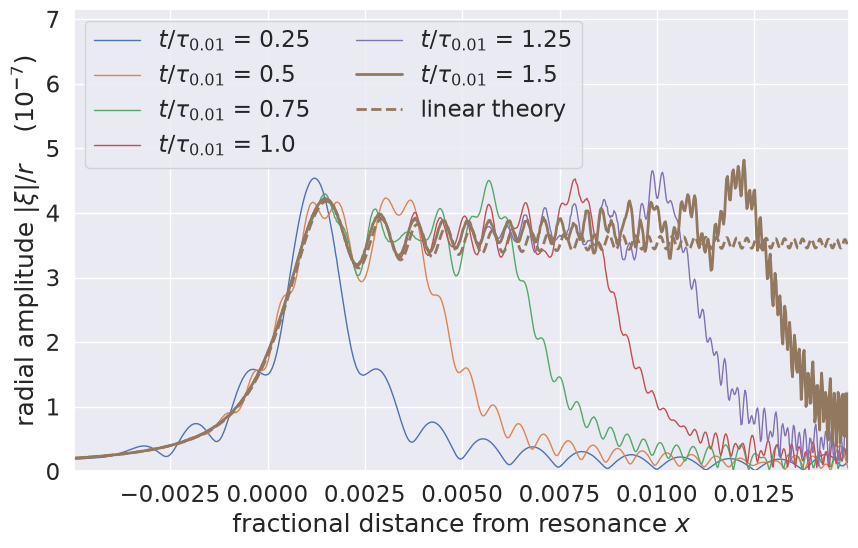

In [6]:
#test 10: each streamline's radial amplitude |xi|/r at six times versus linear theory, |xi|/r of Eqn. (45) (the paper's
#figure, drawn by its own script, paper/figures/density_wave.py); the printed checks compare the end state with Eqn. (45)
Z_w = wave_amplitude(p, sat)
f = paper_figure('density_wave').figure(p, o)
steady = (x > x_lo) & (x < x_hi)
xi_wave = xi - L_L(sat)/x
print('steady stretch: median |xi - L_L/x|/|Z_w| = ', np.round(np.median(np.abs(xi_wave[steady]))/Z_w, 4))
xi_theory = density_wave(sat, sigma, x)
inside = x < -2.0*np.sqrt(2.0*np.pi*sigma/(sat.r_L*sat.D_L))
dev = np.abs(xi - xi_theory)/np.abs(xi_theory)
print('nonwave side (x < -2 eps^1/2): median |xi - theory|/|theory| = ', np.round(np.median(dev[inside]), 4),
    '   largest = ', np.round(dev[inside].max(), 4))
#|xi| keeps only the m-armed part of each streamline's shape: the streamlines' mean osculating eccentricities also hold a
#free part, largest at the ring's edges, where the initial circular orbits are out of balance with the ring's own gravity;
#it is there at the first output, before the wave arrives, and the same in bending_waves.ipynb's ring
e_first = o['e'][0].mean(axis=1)
print('first output: mean eccentricity at the inner edge, mid-ring and outer edge = ', e_first[[0, len(x)//2, -1]])


steady stretch: median k/k_continuum - 1 =  0.0362
k > 0 (trailing) at  345  of  345  streamline pairs in the steady stretch
T/T_L over the last half of the run: mean =  0.993   range =  0.8256  to  1.212


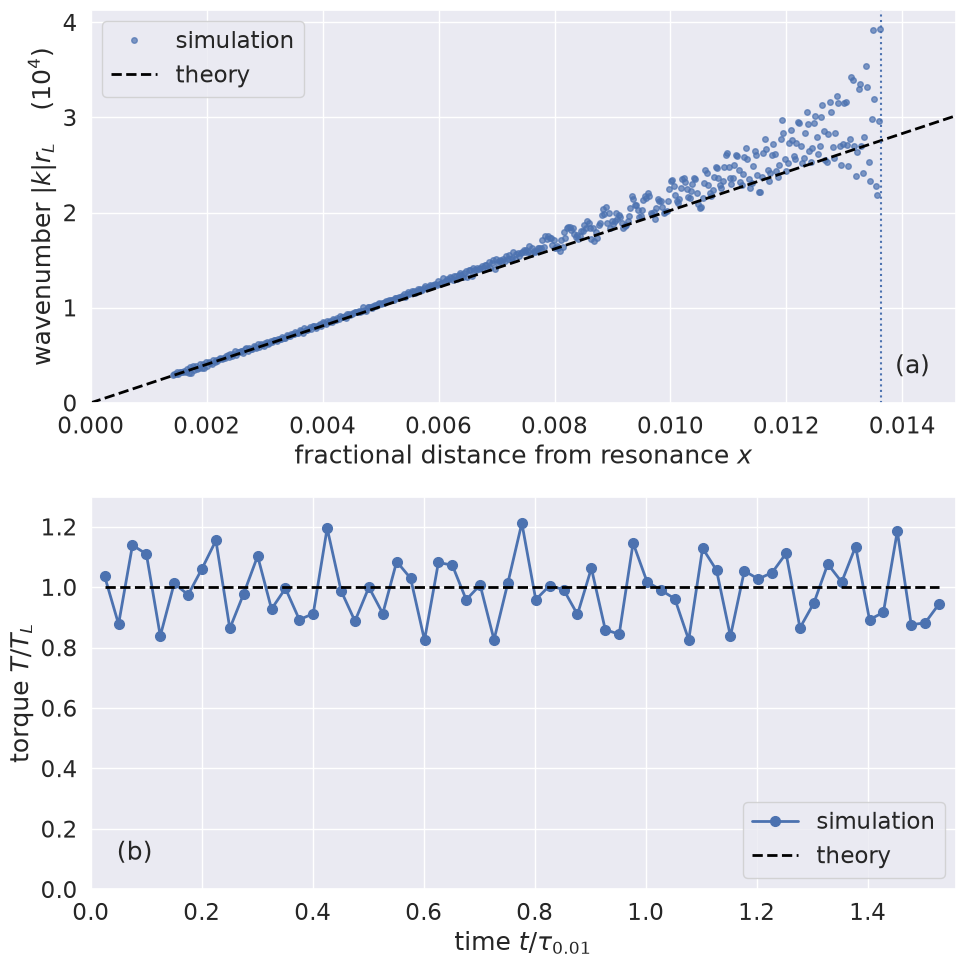

In [7]:
#test 11: (a) the wave's wavenumber k = d(phase of xi - L_L/x)/dr between neighboring streamlines, versus the dispersion
#relation k = x/(epsilon r_L) of Eqn. (40); (b) the satellite's torque on the ring, sum of mu r A_theta, versus
#linear theory's T_L of Eqn. (46) (the paper's figure, drawn by its own script, paper/figures/density_torque.py)
f = paper_figure('density_torque').figure(p, o)
x_mid, k_sim = wavenumber_profile(x, xi_wave, sat.r_L)
sel = (x_mid > x_lo) & (x_mid < x_hi)
print('steady stretch: median k/k_continuum - 1 = ', np.round(np.median(k_sim[sel]/wave_wavenumber(p, sat, x_mid[sel]) - 1.0), 4))
print('k > 0 (trailing) at ', np.sum(k_sim[sel] > 0), ' of ', np.sum(sel), ' streamline pairs in the steady stretch')
torque = np.array([satellite_torque(p, o, k).sum() for k in range(len(o['times']))])
ratio = torque/torque_theory(p, sat)
late = ratio[len(ratio)//2:]
print('T/T_L over the last half of the run: mean = ', np.round(late.mean(), 4), '  range = ', np.round(late.min(), 4),
    ' to ', np.round(late.max(), 4))